<a href="https://colab.research.google.com/github/amsalu2212/DS-Ass4/blob/main/Ass4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Name: Amsalu Tessema**
#**ID Number:2026A8000929002**
# Data Science Assignment 4 Model Comparison and Calibration Lab

**Dataset:** Wisconsin Breast Cancer Diagnostic (WDBC), accessed through Scikit-learn's packaged copy.  
**Positive class:** malignant (1); **negative class:** benign (0).

## Objectives of my assignment is:
- To Compare a strong simple baseline with more complex classifiers.
- To use a frozen split, identical stratified folds, fixed configurations, and paired predictions.
- To Prepare experimental report PR-AUC, ROC-AUC, calibration, Brier score, ECE, and uncertainty intervals.
- To inspect feature-based slices, false positives/false negatives, and a concrete counterexample.
- To select a decision threshold using explicit error costs and a human-review capacity constraint, then run sensitivity analysis.

## Data provenance
Original source: [UCI Machine Learning Repository — Breast Cancer Wisconsin (Diagnostic)]https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
Dear professor,to access the dataset, I used the notebook code `sklearn.datasets.load_breast_cancer(as_frame=True)`
Therefore, a separate data download is not needed. The source dataset is a small, curated diagnostic dataset; do not interpret results as evidence of clinical readiness.
## Frozen evaluation protocol

| Item | Frozen choice |
|---|---|
| Dataset version | Scikit-learn packaged WDBC copy; 569 rows, 30 numeric predictors |
|Split | Stratified 80/20, seed 42 |
| CV | StratifiedKFold(5, shuffle=True, random_state=42) |
| Primary ranking metric | PR-AUC |
| Other metrics | ROC-AUC, Brier, 10-bin ECE, log loss, accuracy/precision/recall/F1 |
| Uncertainty | t intervals over five fold scores; percentile bootstrap intervals on holdout |
| Paired comparison | Same OOF rows resampled jointly for each model difference |
| Threshold policy | Minimize 5×FN + 1×FP subject to ≤20% training alerts |
| Calibration | Quantile-bin reliability diagram; Brier and ECE |
| Hyperparameter budget | Zero search trials; fixed configurations only |

## Execute the full experiment
The Finally the coding part cell is loads the public dataset, freezes the protocol, trains/evaluates all models, writes paired predictions and raw metrics, and generates PR/ROC, calibration, and cost figures.

### Integrated source code - Import necessary Libraries

In [1]:
# First import all necessary modules/libraries
from pathlib import Path
import json, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from scipy.stats import t
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, precision_recall_curve, roc_curve
)
from sklearn.calibration import calibration_curve


### The following code also used for integrated source code Frozen protocol

In [2]:
# -------------------------- 1. Frozen protocol --------------------------
SEED = 42
N_SPLITS = 5
TEST_SIZE = 0.20
N_BOOT = 1000
N_ECE_BINS = 10
FN_COST = 5.0
FP_COST = 1.0
MAX_ALERT_RATE = 0.20
OUTPUT_DIR = Path("ds_a4_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# As we have seen here, since the Dataset source is: UCI Breast Cancer Wisconsin (Diagnostic).
# Reproducible default: use Scikit-learn's packaged copy, write it to CSV, then read it with pandas.
# To use my own copy,  I can to say set USER_CSV_PATH to its exact path and ensure it contains the 30 feature
# columns plus a target column named "malignant" (1=malignant, 0=benign).
USER_CSV_PATH = None  # Example: Path("data/wdbc_dataset.csv")
DATA_CSV_PATH = OUTPUT_DIR / "amsalu_dataset.csv"
UCI_SOURCE = "https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic"

dataset = load_breast_cancer(as_frame=True)
if USER_CSV_PATH is not None and Path(USER_CSV_PATH).exists():
    df = pd.read_csv(USER_CSV_PATH)
    print(f"Loaded user-provided CSV: {USER_CSV_PATH}")
else:
    raw_df = dataset.data.copy()
    raw_df["malignant"] = (dataset.target == 0).astype(int).to_numpy()
    raw_df.to_csv(DATA_CSV_PATH, index=False)
    df = pd.read_csv(DATA_CSV_PATH)
    print(f"Created and imported reproducible CSV: {DATA_CSV_PATH.resolve()}")

# Dataset structure and schema inspection
print("\nDATASET OVERVIEW")
print("Python object type:", type(df))
print("DataFrame shape (rows, columns):", df.shape)
print("Number of observations:", df.shape[0])
print("Number of predictor columns:", df.shape[1] - 1)
print("\nCOLUMN NAMES:")
print(df.columns.tolist())
print("\nFIRST FIVE ROWS:")
display(df.head())
print("\nLAST FIVE ROWS:")
display(df.tail())
print("\nDATA TYPES AND NON-NULL COUNTS:")
df.info()
print("\nMISSING VALUES PER COLUMN:")
display(df.isna().sum().to_frame("missing_count"))
print("\nDUPLICATE ROW COUNT:", int(df.duplicated().sum()))
print("\nDESCRIPTIVE STATISTICS:")
display(df.describe().T.round(3))
print("\nTARGET CLASS COUNTS (0=benign, 1=malignant):")
display(df["malignant"].value_counts().sort_index().rename(index={0:"Benign (0)",1:"Malignant (1)"}).to_frame("count"))

# Separate predictors and target. Keep original feature names for interpretation.
X = df.drop(columns=["malignant"]).copy()
y = df["malignant"].astype(int).rename("malignant")
assert set(y.unique()) == {0, 1}, "Target must be encoded as 0=benign and 1=malignant."

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

# Same frozen split and same StratifiedKFold folds for every candidate model.
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=5000,
                                     class_weight="balanced", random_state=SEED))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=None, min_samples_leaf=2,
        class_weight="balanced", random_state=SEED, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        learning_rate=0.08, max_iter=150, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=SEED
    ),
    "Dummy (stratified)": DummyClassifier(strategy="prior")
}

def ece_score(y_true, probability, n_bins=N_ECE_BINS):
    """Expected calibration error using fixed-width probability bins."""
    yy = np.asarray(y_true)
    pp = np.asarray(probability)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = ((pp >= edges[i]) & (pp <= edges[i+1])) if i == n_bins-1 else (
            (pp >= edges[i]) & (pp < edges[i+1]))
        if mask.any():
            ece += mask.mean() * abs(yy[mask].mean() - pp[mask].mean())
    return float(ece)

def choose_threshold(y_true, probability, fn_cost=FN_COST,
                     fp_cost=FP_COST, max_alert_rate=MAX_ALERT_RATE):
    """Minimize empirical FN/FP cost subject to a maximum alert/review capacity."""
    yy, pp = np.asarray(y_true), np.asarray(probability)
    candidates = np.unique(np.r_[0.0, pp, 1.0])
    best = None
    for threshold in candidates:
        pred = (pp >= threshold).astype(int)
        alert_rate = pred.mean()
        if alert_rate <= max_alert_rate + 1e-12:
            tn, fp, fn, tp = confusion_matrix(yy, pred, labels=[0, 1]).ravel()
            cost = fn_cost * fn + fp_cost * fp
            # Tie-break toward the higher threshold (fewer alerts).
            candidate = (cost, -threshold, threshold)
            if best is None or candidate < best:
                best = candidate
    return float(best[2]) if best is not None else 1.0

def metrics_at_half(name, yy, pp):
    pred = (pp >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yy, pred, labels=[0, 1]).ravel()
    return {
        "model": name, "ROC_AUC": roc_auc_score(yy, pp),
        "PR_AUC": average_precision_score(yy, pp),
        "Brier": brier_score_loss(yy, pp), "ECE_10bin": ece_score(yy, pp),
        "LogLoss": log_loss(yy, pp, labels=[0, 1]),
        "Accuracy_at_0.5": accuracy_score(yy, pred),
        "Precision_at_0.5": precision_score(yy, pred, zero_division=0),
        "Recall_at_0.5": recall_score(yy, pred, zero_division=0),
        "F1_at_0.5": f1_score(yy, pred, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

def bootstrap_ci(y_true, probability, metric, n_boot=N_BOOT, seed=SEED):
    """Percentile row-bootstrap CI; stratified by resampling rows with replacement."""
    yy, pp = np.asarray(y_true), np.asarray(probability)
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(yy), len(yy))
        if len(np.unique(yy[idx])) < 2:
            continue
        values.append(metric(yy[idx], pp[idx]))
    return np.quantile(values, [0.025, 0.975])


Created and imported reproducible CSV: /content/ds_a4_outputs/amsalu_dataset.csv

DATASET OVERVIEW
Python object type: <class 'pandas.core.frame.DataFrame'>
DataFrame shape (rows, columns): (569, 31)
Number of observations: 569
Number of predictor columns: 30

COLUMN NAMES:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'malignant']

FIRST FIVE ROWS:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1



LAST FIVE ROWS:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,1
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,1
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,1
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,1
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,0



DATA TYPES AND NON-NULL COUNTS:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float6

,missing_count
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0



DUPLICATE ROW COUNT: 0

DESCRIPTIVE STATISTICS:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097



TARGET CLASS COUNTS (0=benign, 1=malignant):


,count
malignant,
Benign (0),357
Malignant (1),212


### The following code also used for Dataset exploration and exploratory data analysis(EDA)
These inspects the imported CSV before modelling. The plots are descriptive: the holdout split and model evaluation remain unchanged. The dataset contains 30 numeric predictors and a binary target.

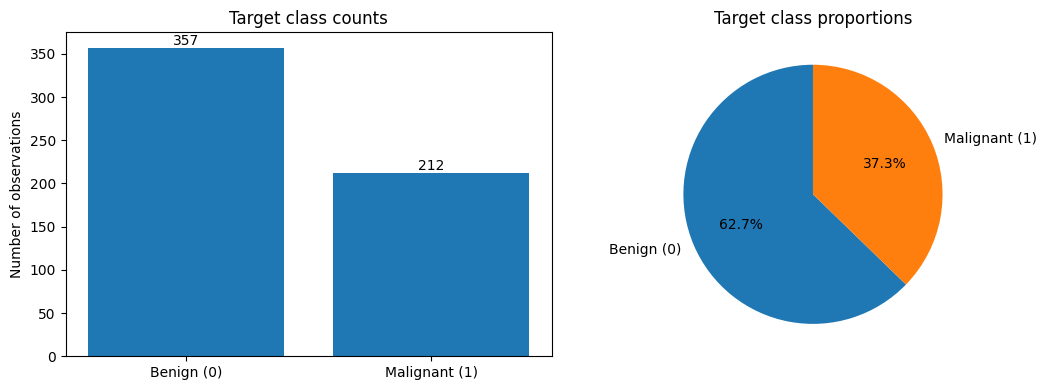

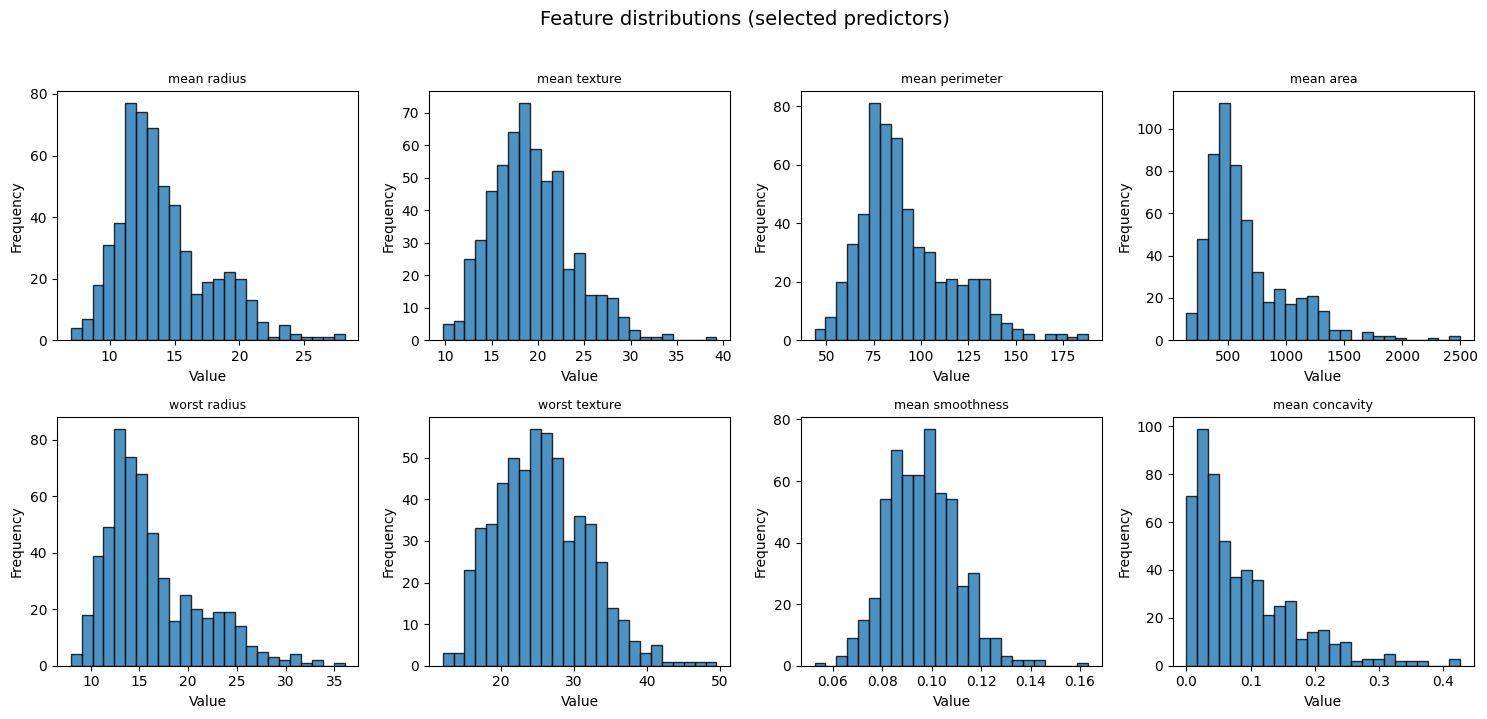

/tmp/ipykernel_4271/2576576500.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(values, labels=["Benign", "Malignant"], showfliers=False)
/tmp/ipykernel_4271/2576576500.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(values, labels=["Benign", "Malignant"], showfliers=False)
/tmp/ipykernel_4271/2576576500.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(values, labels=["Benign", "Malignant"], showfliers=False)
/tmp/ipykernel_4271/2576576500.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support f

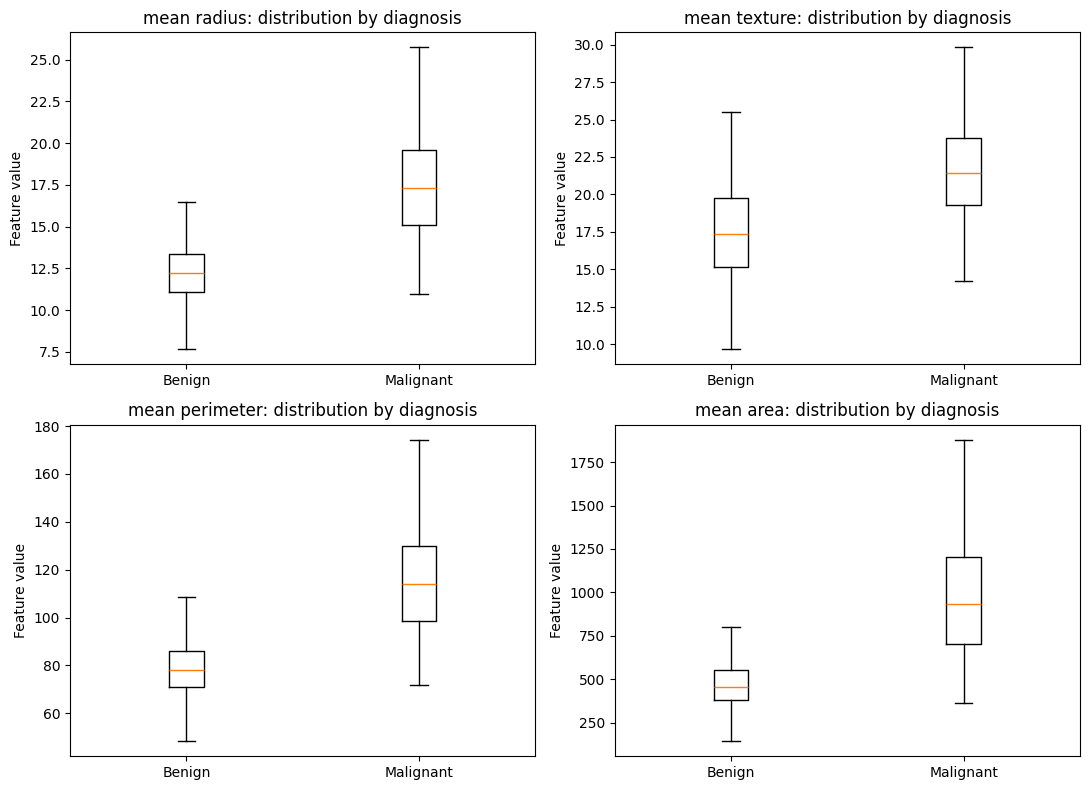

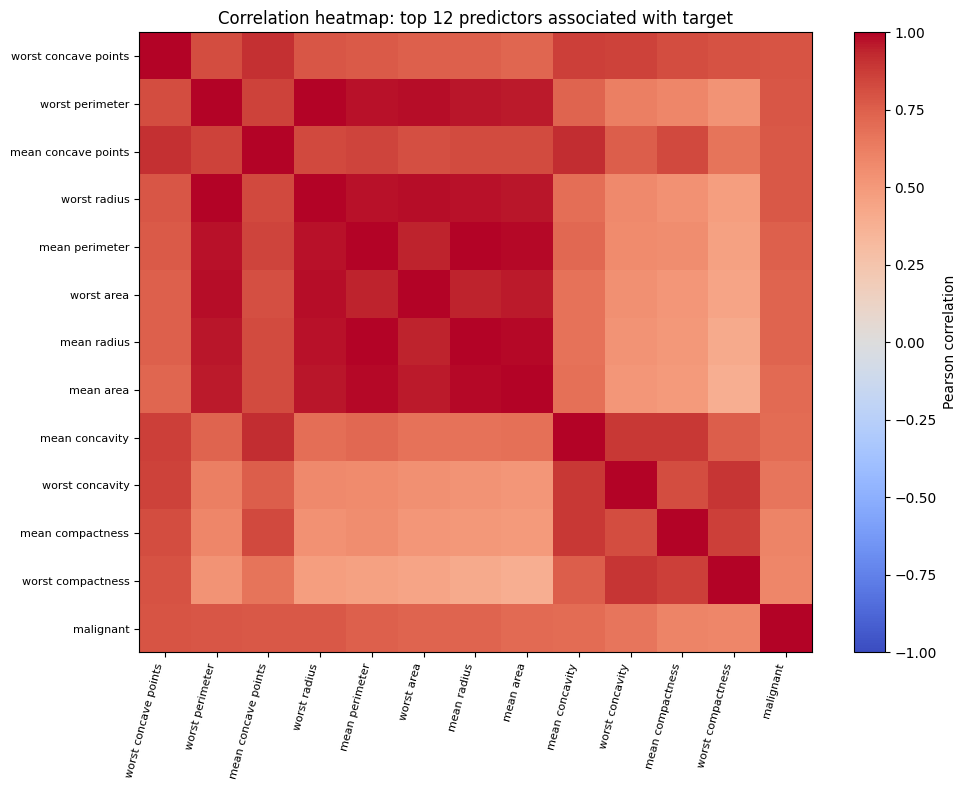

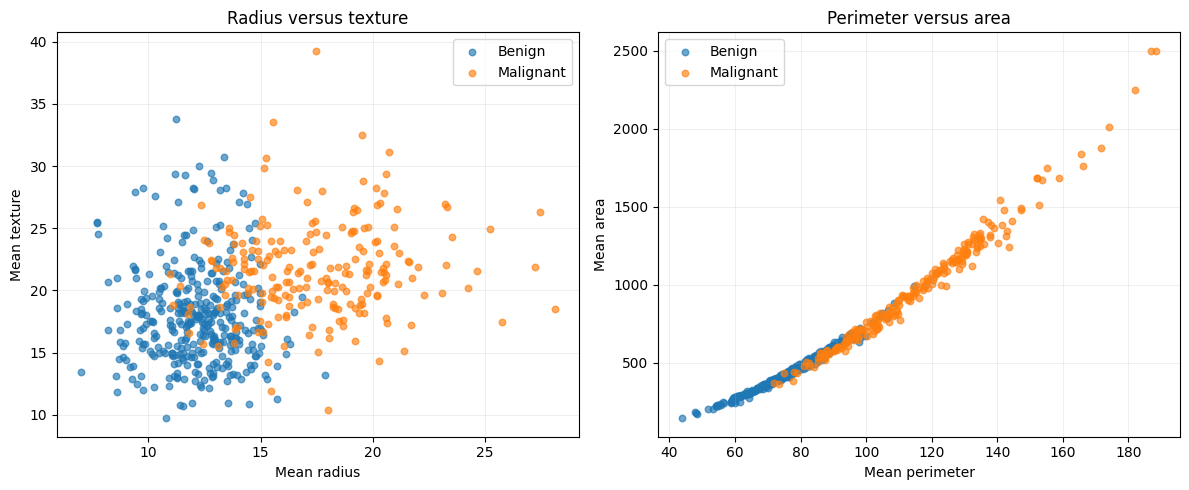

EDA complete. No missing values are expected in this packaged dataset; inspect the table above.


In [3]:
# EDA 1- class distribution and target balance
class_counts = y.value_counts().sort_index()
class_labels = ["Benign (0)", "Malignant (1)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(class_labels, [class_counts.get(0, 0), class_counts.get(1, 0)])
axes[0].set_title("Target class counts")
axes[0].set_ylabel("Number of observations")
for i, v in enumerate([class_counts.get(0, 0), class_counts.get(1, 0)]):
    axes[0].text(i, v + 3, str(v), ha="center")
axes[1].pie([class_counts.get(0, 0), class_counts.get(1, 0)], labels=class_labels,
           autopct="%1.1f%%", startangle=90)
axes[1].set_title("Target class proportions")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_class_distribution.png", dpi=180); plt.show(); plt.close()

# EDA 2 — distributions for representative features
selected_features = ["mean radius", "mean texture", "mean perimeter", "mean area",
                     "worst radius", "worst texture", "mean smoothness", "mean concavity"]
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, col in zip(axes.flat, selected_features):
    ax.hist(X[col], bins=25, edgecolor="black", alpha=0.8)
    ax.set_title(col, fontsize=9); ax.set_xlabel("Value"); ax.set_ylabel("Frequency")
plt.suptitle("Feature distributions (selected predictors)", y=1.02, fontsize=14)
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_feature_histograms.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close()

# EDA 3 — class-conditional boxplots for selected predictors
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, ["mean radius", "mean texture", "mean perimeter", "mean area"]):
    values = [X.loc[y == 0, col], X.loc[y == 1, col]]
    ax.boxplot(values, labels=["Benign", "Malignant"], showfliers=False)
    ax.set_title(f"{col}: distribution by diagnosis"); ax.set_ylabel("Feature value")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_class_boxplots.png", dpi=180); plt.show(); plt.close()

# EDA 4 — correlations among the strongest target-associated predictors
corr_with_target = df.corr(numeric_only=True)["malignant"].drop("malignant").abs().sort_values(ascending=False)
top_corr_features = corr_with_target.head(12).index.tolist()
corr_matrix = df[top_corr_features + ["malignant"]].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(corr_matrix.columns))); ax.set_xticklabels(corr_matrix.columns, rotation=75, ha="right", fontsize=8)
ax.set_yticks(range(len(corr_matrix.index))); ax.set_yticklabels(corr_matrix.index, fontsize=8)
ax.set_title("Correlation heatmap: top 12 predictors associated with target")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_correlation_heatmap.png", dpi=180); plt.show(); plt.close()

# EDA 5 — feature relationship scatterplots, coloured by diagnosis
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for cls, label in [(0, "Benign"), (1, "Malignant")]:
    mask = (y == cls)
    axes[0].scatter(X.loc[mask, "mean radius"], X.loc[mask, "mean texture"],
                    alpha=0.65, s=22, label=label)
    axes[1].scatter(X.loc[mask, "mean perimeter"], X.loc[mask, "mean area"],
                    alpha=0.65, s=22, label=label)
axes[0].set_xlabel("Mean radius"); axes[0].set_ylabel("Mean texture")
axes[1].set_xlabel("Mean perimeter"); axes[1].set_ylabel("Mean area")
for ax in axes: ax.legend(); ax.grid(alpha=0.2)
axes[0].set_title("Radius versus texture"); axes[1].set_title("Perimeter versus area")
plt.tight_layout(); plt.savefig(FIG_DIR / "eda_feature_scatterplots.png", dpi=180); plt.show(); plt.close()

print("EDA complete. No missing values are expected in this packaged dataset; inspect the table above.")


### The following code also used for Model evaluation - paired cross-validation predictions

In [4]:
# --------------------------  Paired CV predictions --------------------
oof_prob = {}
fold_metrics = []
for model_name, estimator in models.items():
    # Each training row receives an out-of-fold prediction from the same fold plan.
    oof_prob[model_name] = cross_val_predict(
        clone(estimator), X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]
    for fold_no, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train), start=1):
        fitted_fold = clone(estimator).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        fold_prob = fitted_fold.predict_proba(X_train.iloc[va_idx])[:, 1]
        fold_y = y_train.iloc[va_idx]
        fold_metrics.append({
            "model": model_name, "fold": fold_no,
            "roc_auc": roc_auc_score(fold_y, fold_prob),
            "pr_auc": average_precision_score(fold_y, fold_prob),
            "brier": brier_score_loss(fold_y, fold_prob)
        })

fold_df = pd.DataFrame(fold_metrics)
fold_df.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv", index=False)
cv_summary = fold_df.groupby("model").agg(
    ROC_AUC_mean=("roc_auc", "mean"), ROC_AUC_sd=("roc_auc", "std"),
    PR_AUC_mean=("pr_auc", "mean"), PR_AUC_sd=("pr_auc", "std"),
    Brier_mean=("brier", "mean"), Brier_sd=("brier", "std")
).reset_index()
for metric in ["roc_auc", "pr_auc", "brier"]:
    lows, highs = [], []
    for model_name in cv_summary["model"]:
        values = fold_df.loc[fold_df.model == model_name, metric].to_numpy()
        mean = values.mean()
        se = values.std(ddof=1) / np.sqrt(len(values))
        critical = t.ppf(0.975, df=len(values)-1)
        lows.append(mean - critical * se)
        highs.append(mean + critical * se)
    cv_summary[f"{metric}_ci_low"] = lows
    cv_summary[f"{metric}_ci_high"] = highs
# ROC-AUC and PR-AUC are bounded [0,1]; interval clipping prevents impossible endpoints.
for col in ["roc_auc_ci_low", "roc_auc_ci_high", "pr_auc_ci_low", "pr_auc_ci_high"]:
    cv_summary[col] = cv_summary[col].clip(0, 1)
cv_summary.to_csv(OUTPUT_DIR / "cv_summary_ci.csv", index=False)

# Paired bootstrap differences on the same OOF rows, against Logistic Regression.
rng = np.random.default_rng(SEED)
paired_rows = []
reference = "Logistic Regression"
for model_name in models:
    if model_name == reference:
        continue
    for metric_name, metric_fn in [
        ("ROC_AUC", roc_auc_score),
        ("PR_AUC", average_precision_score),
        ("Brier", brier_score_loss)
    ]:
        differences = []
        for _ in range(N_BOOT):
            idx = rng.integers(0, len(y_train), len(y_train))
            yy = y_train.to_numpy()[idx]
            if len(np.unique(yy)) < 2:
                continue
            differences.append(
                metric_fn(yy, oof_prob[model_name][idx]) -
                metric_fn(yy, oof_prob[reference][idx])
            )
        point_difference = metric_fn(y_train, oof_prob[model_name]) - metric_fn(
            y_train, oof_prob[reference])
        paired_rows.append({
            "comparison": f"{model_name} minus {reference}",
            "metric": metric_name, "difference": point_difference,
            "paired_bootstrap_ci_low": np.quantile(differences, 0.025),
            "paired_bootstrap_ci_high": np.quantile(differences, 0.975),
            "direction": "higher is better" if metric_name != "Brier" else "lower is better"
        })
pd.DataFrame(paired_rows).to_csv(OUTPUT_DIR / "paired_oof_differences.csv", index=False)


### The following code also used for Freeze selection before holdout

In [5]:
# -------------------------- 3. Freeze selection before holdout -----------
# Select using training-only CV PR-AUC. Do NOT select the winner from holdout metrics.
pr_rank = cv_summary.sort_values("PR_AUC_mean", ascending=False)
selected_model = pr_rank.iloc[0]["model"]
thresholds = {
    name: choose_threshold(y_train, prob, FN_COST, FP_COST, MAX_ALERT_RATE)
    for name, prob in oof_prob.items()
}

# Fit each model on the complete training partition and score the untouched holdout.
fitted_models, test_prob = {}, {}
holdout_rows = []
for model_name, estimator in models.items():
    fitted = clone(estimator).fit(X_train, y_train)
    fitted_models[model_name] = fitted
    probability = fitted.predict_proba(X_test)[:, 1]
    test_prob[model_name] = probability
    holdout_rows.append(metrics_at_half(model_name, y_test, probability))
holdout_metrics = pd.DataFrame(holdout_rows)
holdout_metrics.to_csv(OUTPUT_DIR / "holdout_metrics.csv", index=False)

# Bootstrap uncertainty on holdout rows (descriptive; no tuning on this partition).
boot_rows = []
for model_name, probability in test_prob.items():
    for metric_name, metric_fn in [
        ("ROC_AUC", roc_auc_score),
        ("PR_AUC", average_precision_score),
        ("Brier", brier_score_loss)
    ]:
        low, high = bootstrap_ci(y_test, probability, metric_fn, seed=SEED)
        boot_rows.append({"model": model_name, "metric": metric_name,
                          "ci_low": low, "ci_high": high, "replicates": N_BOOT})
pd.DataFrame(boot_rows).to_csv(OUTPUT_DIR / "holdout_bootstrap_ci.csv", index=False)

# Paired holdout probabilities: each row is the same patient/example for every model.
paired_predictions = pd.DataFrame({
    "row_index": X_test.index, "actual_malignant": y_test.to_numpy()
})
for model_name, probability in test_prob.items():
    paired_predictions[f"prob__{model_name}"] = probability
paired_predictions.to_csv(OUTPUT_DIR / "holdout_probabilities_all_models.csv", index=False)


### The following code also used for calibration and threshold decisions

In [6]:
# --------------------------Calibration and threshold decisions -------
threshold_rows = []
for model_name, probability in test_prob.items():
    threshold = thresholds[model_name]  # selected on training OOF only
    pred = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "model": model_name, "threshold_from_training_oof": threshold,
        "holdout_alert_rate": pred.mean(), "holdout_TP": tp, "holdout_FP": fp,
        "holdout_FN": fn, "holdout_TN": tn,
        "holdout_cost": FN_COST * fn + FP_COST * fp,
        "FN_cost": FN_COST, "FP_cost": FP_COST,
        "training_alert_capacity": MAX_ALERT_RATE
    })
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(OUTPUT_DIR / "threshold_decision.csv", index=False)

sensitivity_rows = []
for model_name, probability in oof_prob.items():
    for fn_cost in [1, 2, 5, 10]:
        for capacity in [0.10, 0.20, 0.30, 0.40]:
            threshold = choose_threshold(y_train, probability, fn_cost, 1, capacity)
            pred = (test_prob[model_name] >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
            sensitivity_rows.append({
                "model": model_name, "FN_cost": fn_cost, "FP_cost": 1,
                "training_capacity": capacity, "threshold": threshold,
                "holdout_alert_rate": pred.mean(),
                "holdout_cost": fn_cost * fn + fp,
                "TP": tp, "FP": fp, "FN": fn, "TN": tn
            })
pd.DataFrame(sensitivity_rows).to_csv(OUTPUT_DIR / "threshold_sensitivity.csv", index=False)


### The following code also used for critical slices and failure types

In [7]:
# --------------------------Critical slices and failure types ----------
# The model was selected using training CV only, not the holdout.
chosen_probability = test_prob[selected_model]
chosen_threshold = thresholds[selected_model]
chosen_prediction = (chosen_probability >= chosen_threshold).astype(int)
error_table = X_test.copy()
error_table["actual_malignant"] = y_test
error_table["predicted_malignant"] = chosen_prediction
error_table["prob_malignant"] = chosen_probability
error_table["error_type"] = np.select(
    [(y_test.to_numpy() == 1) & (chosen_prediction == 0),
     (y_test.to_numpy() == 0) & (chosen_prediction == 1)],
    ["False Negative (missed malignant)", "False Positive (benign flagged)"],
    default="Correct"
)
radius_cut = X_train["mean radius"].median()
texture_cut = X_train["mean texture"].median()
error_table["radius_slice"] = np.where(
    error_table["mean radius"] > radius_cut, "Above train median", "At/below train median")
error_table["texture_slice"] = np.where(
    error_table["mean texture"] > texture_cut, "Above train median", "At/below train median")
error_table.to_csv(OUTPUT_DIR / "holdout_paired_predictions_and_errors.csv", index=False)

slice_rows = []
for column in ["radius_slice", "texture_slice"]:
    for slice_name, group in error_table.groupby(column):
        slice_rows.append({
            "slice_feature": column, "slice": slice_name, "n": len(group),
            "malignant_n": int(group.actual_malignant.sum()),
            "recall_malignant": recall_score(group.actual_malignant,
                                             group.predicted_malignant, zero_division=0),
            "false_negative_n": int(((group.actual_malignant == 1) &
                                     (group.predicted_malignant == 0)).sum()),
            "false_positive_n": int(((group.actual_malignant == 0) &
                                     (group.predicted_malignant == 1)).sum())
        })
slice_table = pd.DataFrame(slice_rows)
slice_table.to_csv(OUTPUT_DIR / "error_slices.csv", index=False)
errors = error_table[error_table.error_type != "Correct"]
if len(errors):
    counterexample = errors.sort_values("prob_malignant", ascending=False).iloc[0]
    print("Counterexample (most confident error):")
    print(counterexample[["error_type", "prob_malignant", "mean radius", "mean texture"]])


Counterexample (most confident error):
error_type        False Negative (missed malignant)
prob_malignant                             0.999532
mean radius                                   16.07
mean texture                                  19.65
Name: 75, dtype: object


### The following code also used for Visualizations in different diagrams

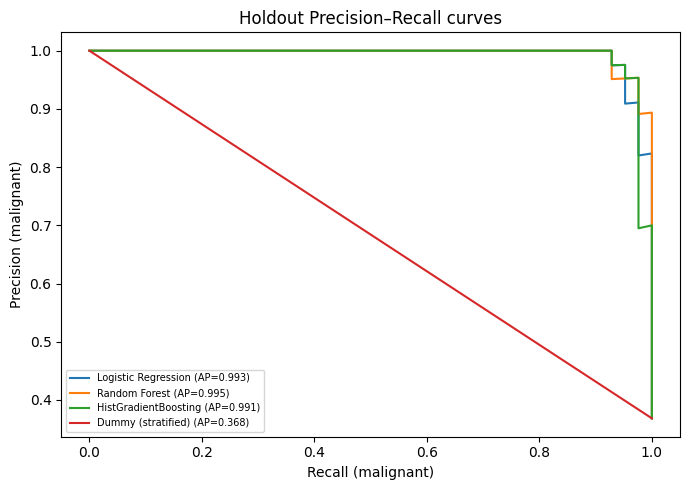

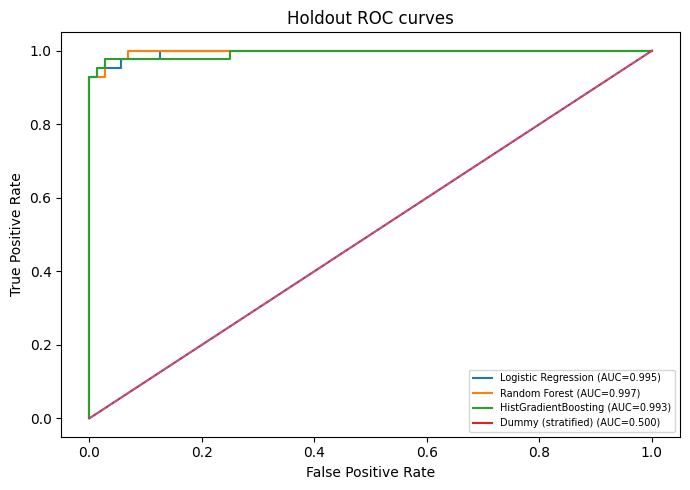

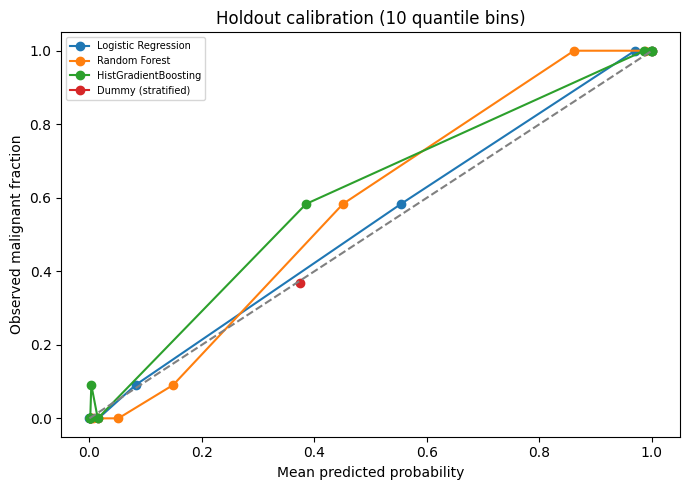

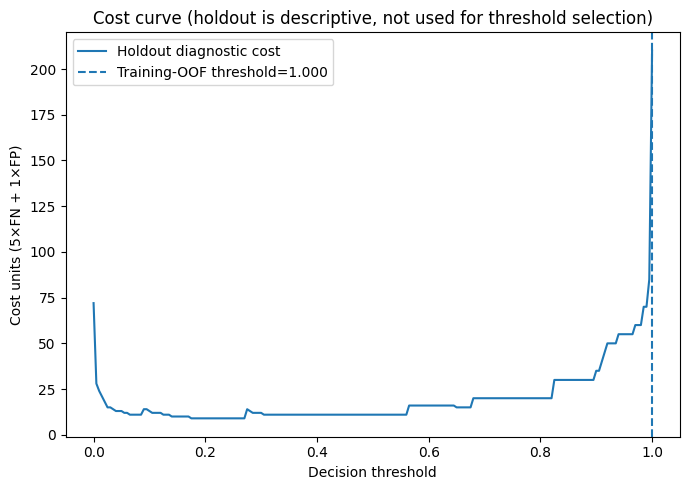

In [8]:
# -------------------------- Visualizations ----------------------------
plt.figure(figsize=(7, 5))
for name, probability in test_prob.items():
    precision, recall, _ = precision_recall_curve(y_test, probability)
    plt.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_test, probability):.3f})")
plt.xlabel("Recall (malignant)"); plt.ylabel("Precision (malignant)")
plt.title("Holdout Precision–Recall curves"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(FIG_DIR / "precision_recall.png", dpi=160); plt.show(); plt.close()

plt.figure(figsize=(7, 5))
for name, probability in test_prob.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probability):.3f})")
plt.plot([0, 1], [0, 1], "--", linewidth=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Holdout ROC curves"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(FIG_DIR / "roc.png", dpi=160); plt.show(); plt.close()

plt.figure(figsize=(7, 5))
for name, probability in test_prob.items():
    observed, predicted = calibration_curve(y_test, probability, n_bins=10, strategy="quantile")
    plt.plot(predicted, observed, marker="o", label=name)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed malignant fraction")
plt.title("Holdout calibration (10 quantile bins)"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(FIG_DIR / "calibration.png", dpi=160); plt.show(); plt.close()

# Cost curve is visualized on holdout only as a diagnostic; it is NOT used to select threshold.
threshold_grid = np.linspace(0, 1, 201)
costs = []
for threshold in threshold_grid:
    pred = (chosen_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    costs.append(FN_COST * fn + FP_COST * fp)
plt.figure(figsize=(7, 5))
plt.plot(threshold_grid, costs, label="Holdout diagnostic cost")
plt.axvline(chosen_threshold, linestyle="--",
            label=f"Training-OOF threshold={chosen_threshold:.3f}")
plt.xlabel("Decision threshold"); plt.ylabel("Cost units (5×FN + 1×FP)")
plt.title("Cost curve (holdout is descriptive, not used for threshold selection)")
plt.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "cost_curve.png", dpi=160); plt.show(); plt.close()


### The following code also used for comparison visualizations

The following figures complement PR, ROC, and calibration curves with fold-level comparisons, uncertainty bars, holdout metric summaries, confusion matrices, error counts, and threshold sensitivity. They use the same model predictions and do not refit or retune models.

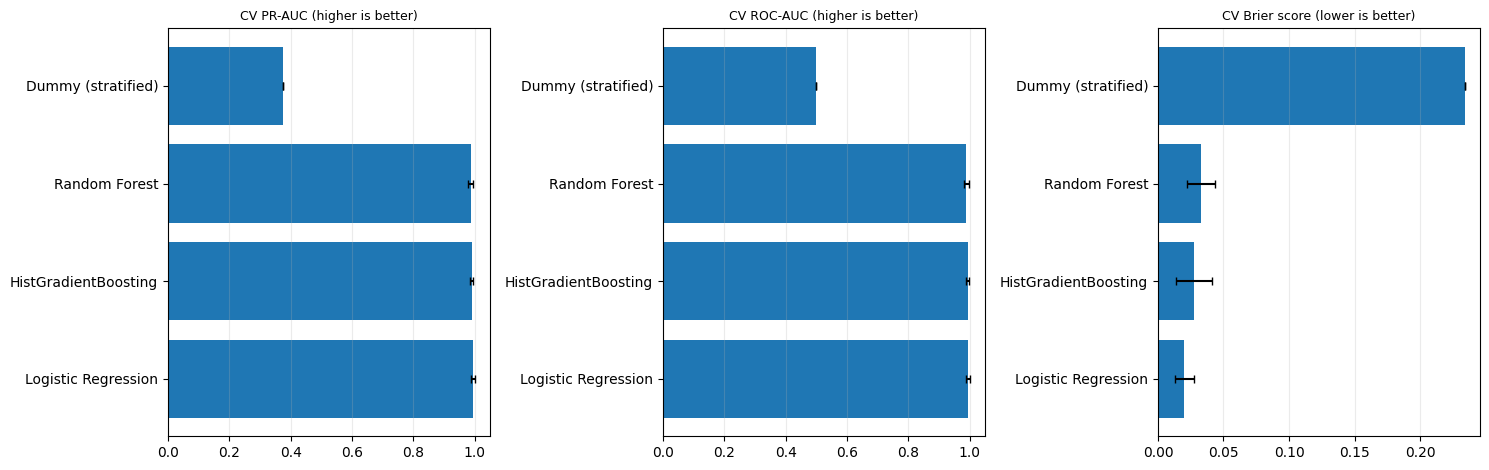

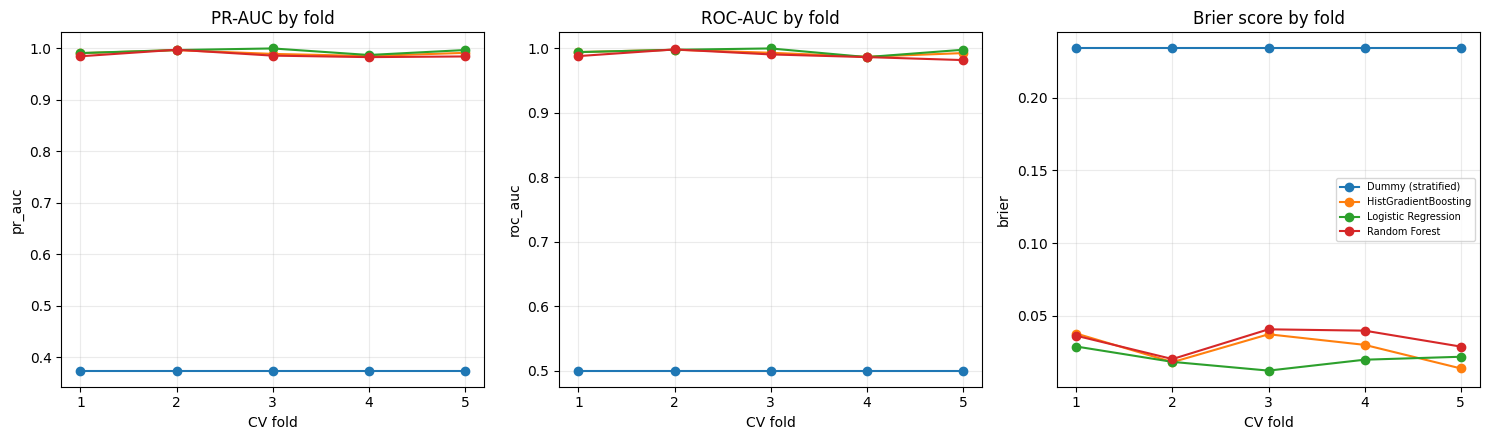

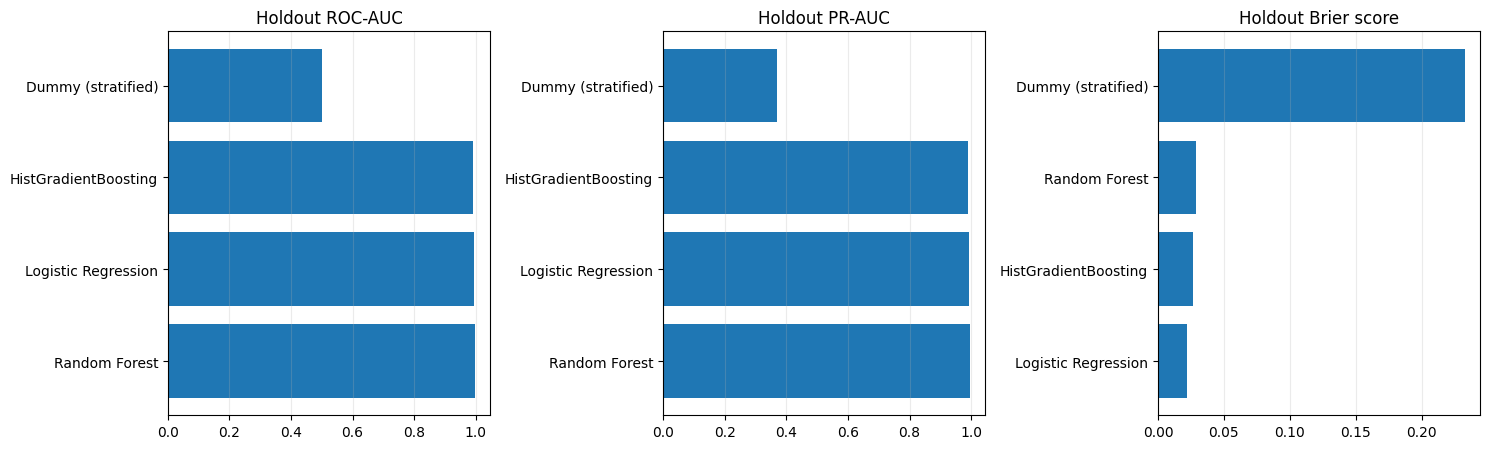

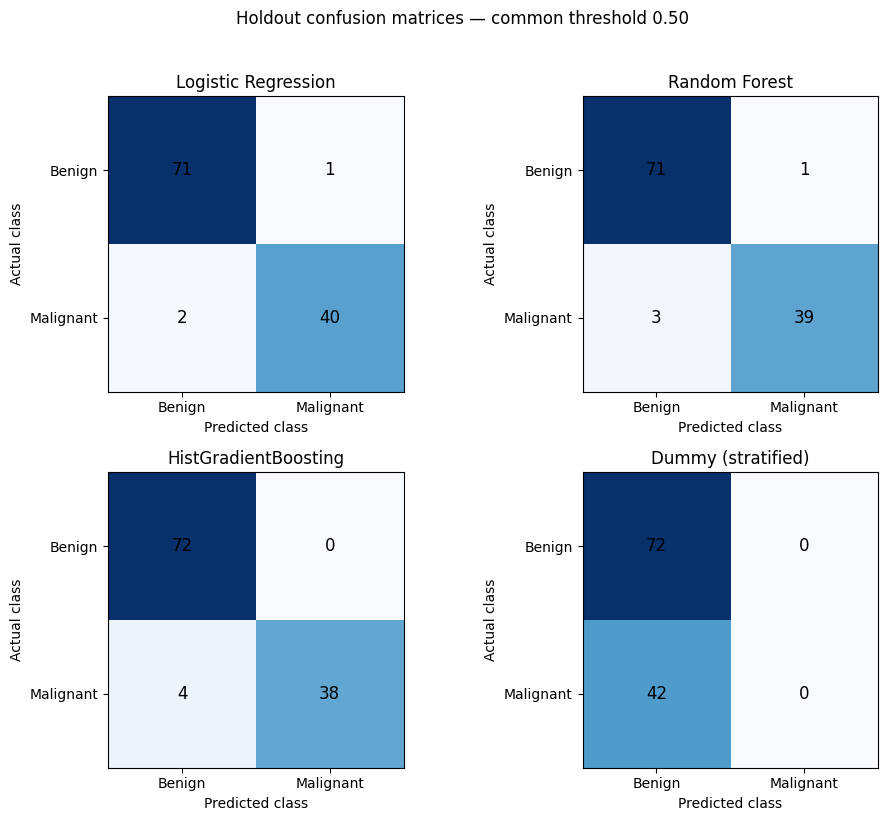

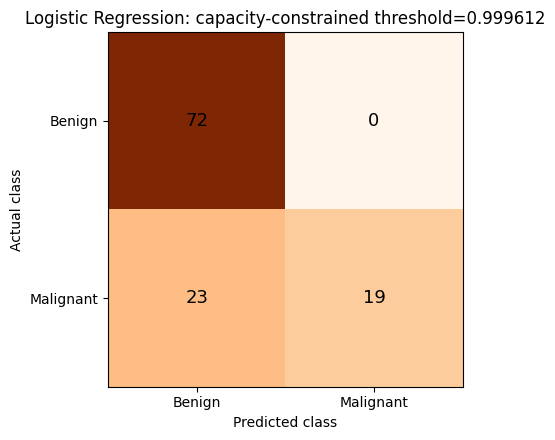

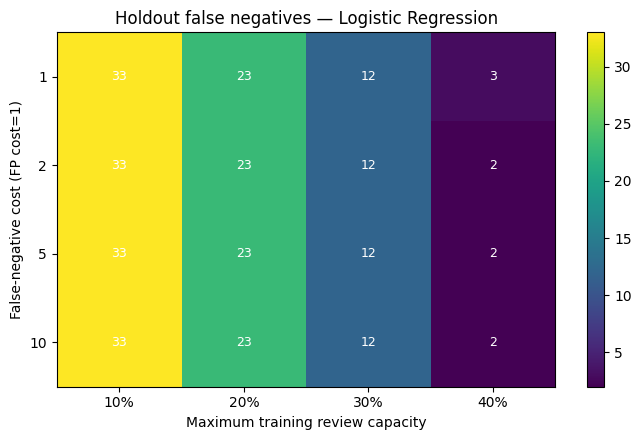

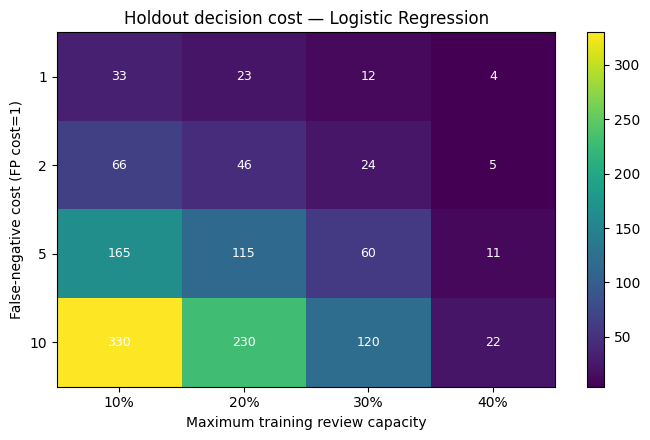

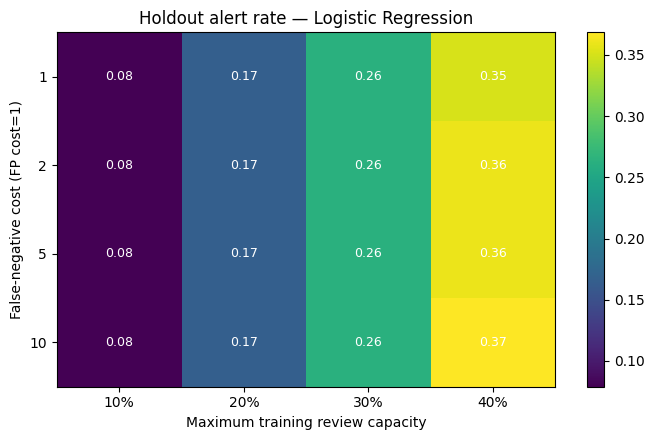

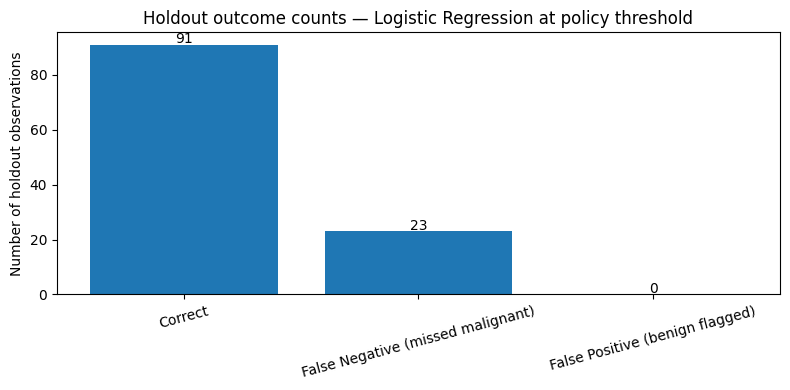

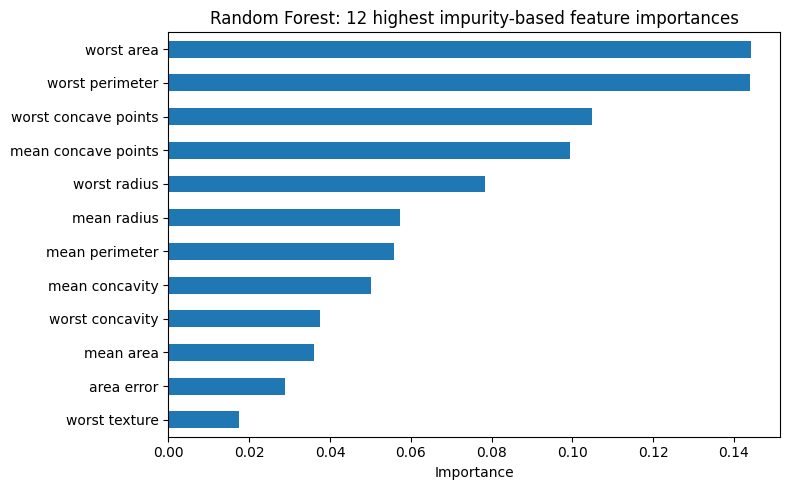

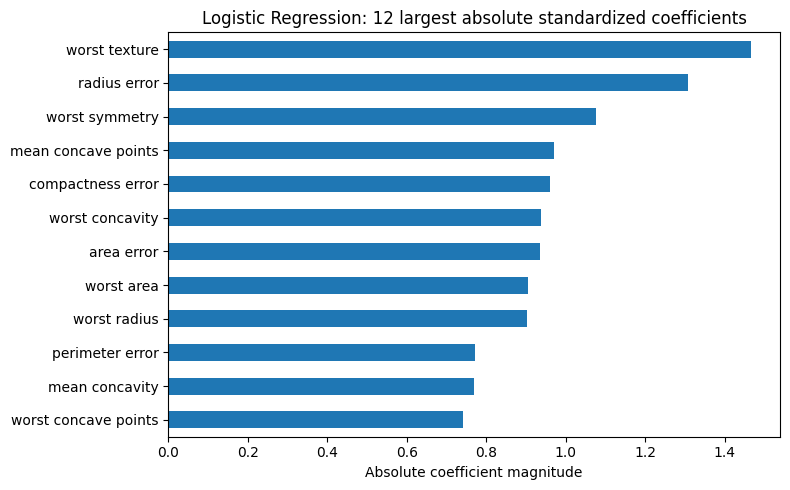

Expanded visual comparison complete. Figures saved in: /content/ds_a4_outputs/figures


In [9]:
# cross-validation means with fold-based 95% t intervals
metric_specs = [
    ("PR_AUC_mean", "pr_auc_ci_low", "pr_auc_ci_high", "CV PR-AUC (higher is better)"),
    ("ROC_AUC_mean", "roc_auc_ci_low", "roc_auc_ci_high", "CV ROC-AUC (higher is better)"),
    ("Brier_mean", "brier_ci_low", "brier_ci_high", "CV Brier score (lower is better)")
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (mean_col, low_col, high_col, title) in zip(axes, metric_specs):
    plot_df = cv_summary.sort_values(mean_col, ascending=(mean_col == "Brier_mean"))
    means = plot_df[mean_col].to_numpy()
    lower = means - plot_df[low_col].to_numpy()
    upper = plot_df[high_col].to_numpy() - means
    ax.barh(plot_df["model"], means, xerr=np.vstack([lower, upper]), capsize=3)
    ax.set_title(title, fontsize=9); ax.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_cv_metrics_with_ci.png", dpi=180); plt.show(); plt.close()

# Comparison 2 — fold-by-fold metric stability
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric, title in zip(axes, ["pr_auc", "roc_auc", "brier"], ["PR-AUC by fold", "ROC-AUC by fold", "Brier score by fold"]):
    for name, grp in fold_df.groupby("model"):
        ax.plot(grp["fold"], grp[metric], marker="o", label=name)
    ax.set_xlabel("CV fold"); ax.set_ylabel(metric); ax.set_title(title); ax.set_xticks(range(1, N_SPLITS+1)); ax.grid(alpha=0.25)
axes[-1].legend(fontsize=7, loc="best")
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_fold_stability.png", dpi=180); plt.show(); plt.close()

# Comparison 3 — holdout ranking and probability-quality metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, metric, title in zip(axes, ["ROC_AUC", "PR_AUC", "Brier"], ["Holdout ROC-AUC", "Holdout PR-AUC", "Holdout Brier score"]):
    ordered = holdout_metrics.sort_values(metric, ascending=(metric == "Brier"))
    ax.barh(ordered["model"], ordered[metric])
    ax.set_title(title); ax.grid(axis="x", alpha=0.25)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_holdout_metrics.png", dpi=180); plt.show(); plt.close()

# Comparison 4 — confusion matrices for all models at the common default threshold 0.50
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, probability) in zip(axes.flat, test_prob.items()):
    pred = (probability >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ax.imshow(cm, cmap="Blues")
    ax.set_title(name); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Benign", "Malignant"]); ax.set_yticklabels(["Benign", "Malignant"])
    ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
    for (i, j), val in np.ndenumerate(cm): ax.text(j, i, str(val), ha="center", va="center", fontsize=12)
plt.suptitle("Holdout confusion matrices — common threshold 0.50", y=1.02)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_confusion_matrices_05.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close()

# Comparison 5 — threshold-policy confusion matrix for selected model
policy_pred = (chosen_probability >= chosen_threshold).astype(int)
policy_cm = confusion_matrix(y_test, policy_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5.5, 4.5)); ax.imshow(policy_cm, cmap="Oranges")
ax.set_title(f"{selected_model}: capacity-constrained threshold={chosen_threshold:.6f}")
ax.set_xticks([0,1]); ax.set_yticks([0,1]); ax.set_xticklabels(["Benign", "Malignant"]); ax.set_yticklabels(["Benign", "Malignant"])
ax.set_xlabel("Predicted class"); ax.set_ylabel("Actual class")
for (i,j), val in np.ndenumerate(policy_cm): ax.text(j,i,str(val),ha="center",va="center",fontsize=13)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_selected_policy_confusion_matrix.png", dpi=180); plt.show(); plt.close()

# Comparison 6 — threshold sensitivity heatmaps for selected model
sens = pd.read_csv(OUTPUT_DIR / "threshold_sensitivity.csv")
sens_sel = sens[sens["model"] == selected_model]
for metric, title, fname in [("FN", "Holdout false negatives", "comparison_threshold_FN_heatmap.png"),
                             ("holdout_cost", "Holdout decision cost", "comparison_threshold_cost_heatmap.png"),
                             ("holdout_alert_rate", "Holdout alert rate", "comparison_threshold_alert_heatmap.png")]:
    pivot = sens_sel.pivot(index="FN_cost", columns="training_capacity", values=metric).sort_index()
    fig, ax = plt.subplots(figsize=(7, 4.5)); im=ax.imshow(pivot.values, aspect="auto", cmap="viridis")
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels([f"{c:.0%}" for c in pivot.columns])
    ax.set_yticks(range(len(pivot.index))); ax.set_yticklabels([str(v) for v in pivot.index])
    ax.set_xlabel("Maximum training review capacity"); ax.set_ylabel("False-negative cost (FP cost=1)")
    ax.set_title(f"{title} — {selected_model}")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]): ax.text(j,i,f"{pivot.iloc[i,j]:.2f}" if metric=="holdout_alert_rate" else f"{pivot.iloc[i,j]:.0f}",ha="center",va="center",color="white",fontsize=9)
    fig.colorbar(im, ax=ax); plt.tight_layout(); plt.savefig(FIG_DIR / fname, dpi=180); plt.show(); plt.close()

# Comparison 7 — error-type counts for the selected operating threshold
error_counts = error_table["error_type"].value_counts().reindex(
    ["Correct", "False Negative (missed malignant)", "False Positive (benign flagged)"], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4)); ax.bar(error_counts.index, error_counts.values)
ax.set_ylabel("Number of holdout observations"); ax.set_title(f"Holdout outcome counts — {selected_model} at policy threshold")
ax.tick_params(axis="x", rotation=15)
for i,v in enumerate(error_counts.values): ax.text(i,v+0.5,str(v),ha="center")
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_error_type_counts.png", dpi=180); plt.show(); plt.close()

# Comparison 8 — model-specific feature importance views (not directly comparable across methods)
rf_importance = pd.Series(fitted_models["Random Forest"].feature_importances_, index=X.columns).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 5)); rf_importance.plot(kind="barh", ax=ax)
ax.set_title("Random Forest: 12 highest impurity-based feature importances"); ax.set_xlabel("Importance")
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_random_forest_feature_importance.png", dpi=180); plt.show(); plt.close()

lr_coef = fitted_models["Logistic Regression"].named_steps["model"].coef_[0]
lr_importance = pd.Series(np.abs(lr_coef), index=X.columns).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(8, 5)); lr_importance.plot(kind="barh", ax=ax)
ax.set_title("Logistic Regression: 12 largest absolute standardized coefficients"); ax.set_xlabel("Absolute coefficient magnitude")
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison_logistic_regression_coefficients.png", dpi=180); plt.show(); plt.close()

print("Expanded visual comparison complete. Figures saved in:", FIG_DIR.resolve())


### The following code also used for Environment and final audit record

In [10]:
### The following code also used for Environment and final audit record ----------
environment = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__, "scipy": scipy.__version__,
    "matplotlib": plt.matplotlib.__version__, "seed": SEED,
    "folds": N_SPLITS, "test_size": TEST_SIZE, "bootstrap_replicates": N_BOOT,
    "dataset": "Wisconsin Breast Cancer Diagnostic (scikit-learn packaged copy)",
    "dataset_source": "https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic",
    "rows": int(len(X)), "features": int(X.shape[1]),
    "positive_class": "malignant (1)", "negative_class": "benign (0)",
    "selected_model_by_training_cv_pr_auc": selected_model,
    "selected_threshold_for_operational_rule": chosen_threshold
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))

print("\nCROSS-VALIDATION SUMMARY")
display(cv_summary.round(4))
print("\nUNTOUCHED HOLDOUT METRICS (threshold 0.50)")
display(holdout_metrics.round(4))
print("\nTHRESHOLD DECISION RECORD")
display(threshold_table.round(4))
print("\nERROR SLICES")
display(slice_table.round(4))
print(f"\nSelected model (training CV PR-AUC only): {selected_model}")
print(f"Threshold: {chosen_threshold:.6f}; costs: FN={FN_COST}, FP={FP_COST}; "
      f"training alert capacity={MAX_ALERT_RATE:.0%}")
print(f"Outputs written to: {OUTPUT_DIR.resolve()}")



CROSS-VALIDATION SUMMARY


,model,ROC_AUC_mean,ROC_AUC_sd,PR_AUC_mean,PR_AUC_sd,Brier_mean,Brier_sd,roc_auc_ci_low,roc_auc_ci_high,pr_auc_ci_low,pr_auc_ci_high,brier_ci_low,brier_ci_high
0,Dummy (stratified),0.5000,0.0000,0.3736,0.0000,0.2340,0.0000,0.5000,0.5000,0.3736,0.3736,0.2340,0.2340
1,HistGradientBoosting,0.9931,0.0039,0.9907,0.0041,0.0273,0.0110,0.9882,0.9979,0.9856,0.9958,0.0136,0.0409
2,Logistic Regression,0.9954,0.0053,0.9944,0.0052,0.0201,0.0060,0.9888,1.0000,0.9880,1.0000,0.0126,0.0275
3,Random Forest,0.9892,0.0061,0.9872,0.0059,0.0330,0.0086,0.9816,0.9967,0.9799,0.9945,0.0223,0.0437



UNTOUCHED HOLDOUT METRICS (threshold 0.50)


,model,ROC_AUC,PR_AUC,Brier,ECE_10bin,LogLoss,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5,TN,FP,FN,TP
0,Logistic Regression,0.9954,0.9931,0.0222,0.0253,0.0786,0.9737,0.9756,0.9524,0.9639,71,1,2,40
1,Random Forest,0.9970,0.9952,0.0290,0.0556,0.1085,0.9649,0.9750,0.9286,0.9512,71,1,3,39
2,HistGradientBoosting,0.9931,0.9912,0.0269,0.0290,0.1059,0.9649,1.0000,0.9048,0.9500,72,0,4,38
3,Dummy (stratified),0.5000,0.3684,0.2327,0.0052,0.6582,0.6316,0.0000,0.0000,0.0000,72,0,42,0



THRESHOLD DECISION RECORD


,model,threshold_from_training_oof,holdout_alert_rate,holdout_TP,holdout_FP,holdout_FN,holdout_TN,holdout_cost,FN_cost,FP_cost,training_alert_capacity
0,Logistic Regression,0.9996,0.1667,19,0,23,72,115.0,5.0,1.0,0.2
1,Random Forest,0.9770,0.1930,22,0,20,72,100.0,5.0,1.0,0.2
2,HistGradientBoosting,0.9980,0.1930,22,0,20,72,100.0,5.0,1.0,0.2
3,Dummy (stratified),1.0000,0.0000,0,0,42,72,210.0,5.0,1.0,0.2



ERROR SLICES


,slice_feature,slice,n,malignant_n,recall_malignant,false_negative_n,false_positive_n
0,radius_slice,Above train median,58,40,0.4750,21,0
1,radius_slice,At/below train median,56,2,0.0000,2,0
2,texture_slice,Above train median,51,33,0.4545,18,0
3,texture_slice,At/below train median,63,9,0.4444,5,0



Selected model (training CV PR-AUC only): Logistic Regression
Threshold: 0.999612; costs: FN=5.0, FP=1.0; training alert capacity=20%
Outputs written to: /content/ds_a4_outputs


**Limitations:** Dear professor Tiejian, The dataset I used is too Small, curated, older diagnostic dataset; no external validation; no clinical workflow, prevalence, calibration transport, or decision-maker study; model scores must not be used for diagnosis.
Since the dataset is small I am using Classical machine learning algorithms Just I am using for practicing for EDA. and the assignment 4 indeed.
